# Laboratorio 4A · Procesamiento y análisis clásico de imágenes

**MantenIA**, la empresa ficticia de mantenimiento industrial del curso, mantiene la estación de inspección visual de una línea que envasa **cápsulas blandas** para un cliente farmacéutico. Antes de empacar cada lote, una cámara toma una foto desde arriba y un programa cuenta las cápsulas. El cliente se queja: el conteo no coincide con el que hacen a mano. MantenIA le asignó a usted la tarea de ajustar el programa.

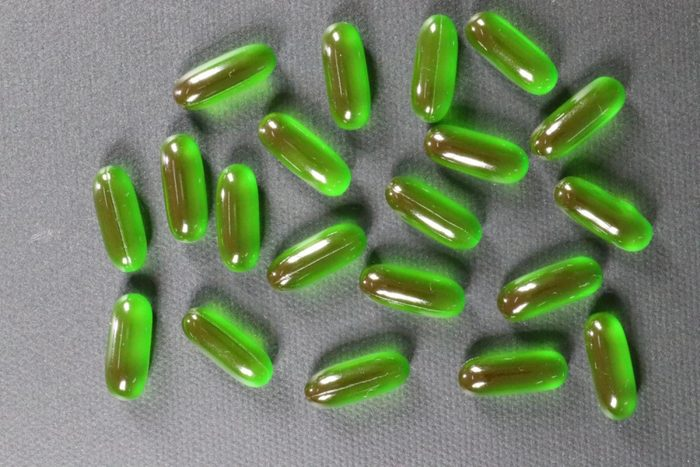

*Foto: conjunto VisA (Zou et ál., 2022), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es), reducida. Las fotos son reales y públicas; MantenIA y su cliente son ficticios.*

El programa es un **pipeline clásico**: etapas que convierten la foto en números, separan las cápsulas del fondo y las cuentan. Nadie lo entrenó con ejemplos: cada etapa tiene **parámetros** que una persona elige mirando la imagen que produce.

En este laboratorio usted:
* Verá una foto como lo que es para la máquina: tablas de números.
* Usará el **histograma** para elegir con qué tabla trabajar y dónde poner el **umbral**.
* Ajustará el filtrado y la **morfología** hasta que cada cápsula quede en su propia región, y lo comprobará contra un **conteo hecho a mano**.
* Separará cápsulas que se tocan y pondrá a prueba su configuración con una lámpara mal ubicada.
* **Medirá** las cápsulas para rechazar una deforme, y verá por qué medir en milímetros exige calibrar la cámara.

| | |
| :--- | :--- |
| **Resultado de aprendizaje** | RA5: construir soluciones de percepción visual combinando procesamiento clásico de imágenes y modelos preentrenados (este laboratorio cubre la parte clásica; el 4B, los modelos). |
| **Tiempo** | 60 minutos en clase (secciones 0 a 9.1) y unos 30 en casa (el final de la sección 8, la 9.2, los análisis ✏️ y la 12). En clase, escriba cada análisis en una frase y complételo en casa. La sección 10 es el punto de partida del trabajo independiente TI-1 de esta sesión. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian valores en las celdas marcadas con ✏️. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_4A.csv`, al inicio de la semana 3 del curso (sección 12). |

## Contenido

* [Antes de empezar](#0) · *en clase, 5 min*
* [1 - El caso: la estación que cuenta mal](#1) · *en clase, 2 min*
* [2 - Una imagen es una tabla de números](#2) · *en clase, 5 min*
* [3 - El pipeline, etapa por etapa](#3) · *en clase, 6 min*
* [4 - El histograma y el canal](#4) · *en clase, 6 min*
* [5 - Contar a mano y comparar](#5) · *en clase, 6 min*
* [6 - Ajustar y observar](#6) · *en clase, 10 min*
* [7 - Cápsulas que se tocan](#7) · *en clase, 9 min*
* [8 - Una lámpara a un lado](#8) · *en clase, 5 min; el final, para casa*
* [9 - Medir y decidir](#9) · *en clase, 6 min (9.1); para casa, 12 min (9.2)*
* [10 - Su propia fotografía](#10) · *para casa, trabajo independiente TI-1*
* [11 - Inténtelo usted mismo: el límite del pipeline](#11) · *opcional*
* [12 - Entrega y criterios](#12) · *para casa, 3 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️: en ellas se cambian números o palabras entre comillas, nunca el resto del código. Este laboratorio no usa ningún LLM ni necesita claves.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (solo si no puede usar VS Code)</summary>

1. Pida al docente el archivo `lab_4A_pipeline_clasico.zip` y abra el notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Ejecute la celda siguiente: descomprime la carpeta y usa las librerías que Colab ya trae.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte (OpenCV y scikit-image). La primera vez descarga unos 95 MB.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt (OpenCV y scikit-image)
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_4A_pipeline_clasico.zip").extractall("/content")
    os.chdir("/content/lab_4A_pipeline_clasico")
import entorno
entorno.preparar()

El laboratorio usa tres módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `inspeccion` tiene el pipeline: lee la imagen, aplica cada etapa con sus parámetros, compara el resultado con el conteo de referencia, mide las cápsulas y lleva la bitácora de sus intentos.
* `vista` dibuja las figuras: las etapas lado a lado, los histogramas, la cuadrícula para contar y las regiones coloreadas.
* `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import inspeccion as insp
import vista
import presentacion as p

<a id='1'></a>
## 1 - El caso: la estación que cuenta mal

Las cápsulas de un lote caen sobre una banda cubierta con una tela gris, una cámara fija toma una foto desde arriba y el programa cuenta. El conteo queda en el registro del lote: una cápsula de más o de menos es una queja del cliente, que además pide **rechazar las cápsulas deformes**.

* Ejecute la siguiente celda para ver la foto de un lote.

In [ ]:
# Cargar y mostrar la foto principal del laboratorio
foto = insp.cargar("capsulas_principal.jpg")
vista.mostrar_imagen(foto, "Un lote: cápsulas verdes sobre la tela gris de la banda")

<a id='2'></a>
## 2 - Una imagen es una tabla de números

Para la máquina, una foto es una tabla. Cada casilla es un **píxel**, y su valor dice cuánta luz llegó: 0 es negro y 255 es blanco. Una foto **a color** son tres tablas, una por color primario: rojo (**R**), verde (**G**) y azul (**B**). De ellas se calculan otras dos que importan hoy:
* **gris:** el brillo del píxel, un promedio ponderado de R, G y B;
* **saturación:** qué tan distintos son entre sí R, G y B. Un gris tiene saturación cercana a 0, y un color puro, cercana a 255.

<details>
<summary><b>Para profundizar: de dónde sale la saturación</b></summary>

La saturación es una de las tres componentes del espacio de color **HSV** (Smith, 1978): matiz (*hue*), saturación y valor. OpenCV la calcula, para cada píxel, como 255 × (máximo − mínimo) / máximo de sus tres valores R, G y B. Si los tres son iguales, como en un gris, da 0.

</details>

**Desglose del experimento.** La celda siguiente marca tres zonas: **A**, tela; **B**, una cápsula; y **C**, un recorte de 12 × 8 píxeles que cruza el borde de una cápsula. Muestra los valores de C uno por uno y el promedio de cada canal en A y en B.

* Ejecute la siguiente celda para ver la foto como números.

In [ ]:
# Mostrar tres zonas de la foto: sus píxeles uno por uno y el promedio de cada canal
vista.mostrar_pixeles(foto)

**Análisis.** En C, el valor cae de unos 170 en la tela a unos 110 en la cápsula: un borde es un salto en la tabla. En la tabla de promedios, la tela y la cápsula quedan a pocas decenas de distancia en **gris**, pero muy lejos en **saturación**: cerca de 0 la tela y de 190 la cápsula. Guarde esta observación para la sección 4.

<a id='3'></a>
## 3 - El pipeline, etapa por etapa

El programa sigue las etapas clásicas del procesamiento de imágenes. Cada una usa uno o varios parámetros:

| Etapa | Qué hace aquí | Parámetros |
| :--- | :--- | :--- |
| **Adquisición** | La foto. La cámara, la luz y la tela ya están dadas | — |
| **Preproceso** | Elige una tabla (el canal) y la suaviza para quitar ruido fino, como la textura de la tela | `canal`, `suavizado` |
| **Segmentación** | Separa objeto y fondo: cada píxel pasa a blanco (cápsula) o negro (fondo) según un **umbral**. Después, la **morfología** limpia esa imagen en blanco y negro | `umbral`, `apertura`, `cierre`, `rellenar` |
| **Representación y descripción** | Agrupa los píxeles blancos que se tocan en **regiones** y mide cada una | `area_minima`, `separar`, `distancia_minima` |
| **Decisión** | Cuenta las regiones y rechaza las que no tienen la forma esperada | (sección 9) |

La figura de la celda siguiente tiene seis paneles numerados. En el panel 4 (el umbral), **blanco** es lo que el pipeline cree que es cápsula, y **negro**, fondo. El pipeline decide solo si las cápsulas son lo claro o lo oscuro de la foto: supone que el borde de la foto es fondo.

**Desglose del experimento.** La celda siguiente corre el pipeline con la configuración que traía la estación: el canal **gris** y el umbral de **Otsu**, un método que elige el umbral solo (lo verá en la sección 4). Muestra las seis etapas lado a lado y, debajo, las regiones numeradas sobre la foto.

* Ejecute la siguiente celda para correr el pipeline como lo dejó el proveedor de la estación.

In [ ]:
# Correr el pipeline con la configuración inicial de la estación (canal gris)
PARAMETROS = dict(insp.PARAMETROS_INICIALES)
p.mostrar_tabla([PARAMETROS], titulo="Configuración inicial")
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="3", con_referencia=False)

**Análisis.** Cerca de 390 regiones: muchísimas más que las cápsulas de la foto. Mire el panel 4: casi toda la tela de la derecha quedó en blanco, como si fuera cápsula, y las cápsulas quedaron cortadas. El problema no está en el conteo, sino antes: en la tabla elegida y en dónde cayó el umbral.

<a id='4'></a>
## 4 - El histograma y el canal

El **histograma** de una tabla cuenta cuántos píxeles tienen cada valor, de 0 a 255. Si fondo y objeto son bien distintos, muestra **dos montañas**, y el umbral debe caer en el valle entre ellas. El **método de Otsu** (1979) lo busca solo: prueba todos los umbrales y elige el que deja los dos grupos más compactos. Si no hay un valle limpio, igual elige un umbral, pero corta donde no debe.

**Desglose del experimento.** La celda siguiente muestra el canal gris y el de saturación, cada uno con su histograma y con el umbral que elegiría Otsu (línea naranja).

* Ejecute la siguiente celda para comparar los dos histogramas.

In [ ]:
# Comparar el histograma del canal gris con el de la saturación, con el umbral de Otsu de cada uno
vista.mostrar_histogramas(foto, ["gris", "saturacion"])

**Análisis.** En **gris** hay dos montañas, pero se tocan. La tela de la derecha está en sombra: allí es tan oscura como las cápsulas y queda del lado equivocado del umbral. Es la mancha blanca del panel 4 en la sección 3. En **saturación**, la tela es una montaña angosta pegada al 0, las cápsulas están muy arriba, y entre las dos hay un valle ancho: la sombra no cambia la saturación. Elegir el canal es la primera decisión de diseño, y se toma mirando el histograma.

<details>
<summary><b>Pista</b></summary>

Recuerde la tabla de promedios de la sección 2: ¿en qué canal la tela y la cápsula están más lejos?

</details>

* Escriba en `CANAL` el canal que separa mejor la tela de las cápsulas y ejecute la celda.

In [ ]:
# ✏️ Elija el canal: "gris", "saturacion", "rojo", "verde" o "azul"
CANAL = "gris"
insp.comprobar_canal(CANAL, foto)

**Desglose del experimento.** La celda siguiente corre el pipeline otra vez, cambiando solo el canal.

* Ejecute la siguiente celda para ver el efecto del canal.

In [ ]:
# Correr el pipeline con el canal elegido; el resto de la configuración no cambia
PARAMETROS["canal"] = CANAL
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="4", con_referencia=False)

**Análisis.** Con la saturación, las regiones caen de cientos a poco más de veinte, y ya se ven cápsulas enteras. ¿Están bien contadas? Un número cercano no lo garantiza: dos cápsulas unidas y un reflejo suelto también suman dos.

<a id='5'></a>
## 5 - Contar a mano y comparar

Un pipeline cuenta lo que **se parece** a lo que busca, no lo que busca. Por eso se valida contra un **conteo hecho a mano**.

**Desglose del experimento.** La celda siguiente muestra la foto con una cuadrícula. Cuente las cápsulas casilla por casilla y sume; una cápsula que cruza una línea cuenta donde está su centro.

* Ejecute la siguiente celda para ver la cuadrícula.

In [ ]:
# Mostrar la foto con una cuadrícula para contar a mano
vista.mostrar_cuadricula(foto)

* Escriba su conteo en `CONTEO_A_MANO` (un número, sin comillas) y ejecute la celda.

In [ ]:
# ✏️ Su conteo a mano de la foto principal
CONTEO_A_MANO = None
insp.comprobar_conteo(CONTEO_A_MANO, "capsulas_principal.jpg")

El docente hizo el mismo conteo y marcó el centro de cada cápsula. Con esos centros, el notebook compara **cápsula por cápsula**, no solo el total:
* **azul:** la región contiene exactamente una cápsula. Es lo que se busca;
* **rojo:** junta dos o más cápsulas, y el total se queda corto;
* **naranja, con un círculo:** no contiene ninguna cápsula (un fragmento, un reflejo o tela), y el total se infla;
* **X magenta:** una cápsula que ninguna región cubre.

Desde ahora, cada corrida se compara así.

* Ejecute la siguiente celda para comparar la configuración actual con la referencia.

In [ ]:
# Comparar la configuración actual con la referencia, cápsula por cápsula
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="5", etapas=False, conteo_a_mano=CONTEO_A_MANO)

**Análisis.** La mayoría de las regiones son azules, pero hay rojas y naranjas. Mire las rojas: el verde de las cápsulas se refleja en la tela y forma un **halo** que une a las vecinas. Las naranjas son trozos sueltos de ese halo o de los bordes.

<a id='6'></a>
## 6 - Ajustar y observar

La meta: **cada cápsula en su propia región, y ninguna región de más**. Los parámetros de esta sección actúan sobre la segmentación:

| Parámetro | Qué hace | Valores para probar |
| :--- | :--- | :--- |
| `umbral` | El valor que separa cápsula y fondo. Un número **fijo** se usa igual en todas las fotos; `"otsu"` lo recalcula en cada foto, y `"adaptativo"` calcula uno distinto en cada zona, con sus vecinos | `"otsu"` o un número de 100 a 200 |
| `apertura` | **Erosión** (encoger cada región blanca, quitándole un borde de ese tamaño) seguida de **dilatación** (engordarla otra vez lo mismo). Lo pequeño desaparece al encoger y no vuelve: borra manchas y corta puentes delgados entre regiones | 3, 5, 7, 9 |
| `rellenar` | Tapa los huecos cerrados dentro de una región, como los que deja un reflejo | `True` o `False` |
| `area_minima` | Descarta las regiones con menos píxeles que este valor. Una cápsula ocupa unos 8000 | 500 a 3000 |
| `suavizado`, `cierre` | El suavizado promedia cada píxel con sus vecinos; el cierre es una dilatación seguida de erosión, que tapa grietas pero puede unir regiones vecinas | No hace falta cambiarlos |

**Desglose del experimento.** Cambie **un parámetro a la vez**, ejecute y mire la comparación. Un orden que funciona:
1. `apertura` en 7;
2. `rellenar` en `True` y `area_minima` en 2500, juntos. En esta foto quizá no cambien el conteo, pero tapan los huecos de los reflejos y quitan fragmentos que aparecerán en las secciones 8 y 9;
3. el `umbral`: un número como 130 y luego 150, en lugar de `"otsu"`.

La bitácora registra cada corrida. La meta de esta sección es quedar, como mucho, con **un par de cápsulas unido**; el notebook le avisa cuando la cumpla.

<details>
<summary><b>Pista</b></summary>

La apertura y el área mínima quitan las regiones naranjas; rellenar tapa los huecos de los reflejos. Para las rojas, mire el histograma de la saturación: el halo es menos saturado que la cápsula, así que un umbral fijo más alto que el de Otsu lo deja por fuera. Si sube mucho el umbral, las cápsulas se parten y vuelven las naranjas. Sin importar lo que haga, **al menos un par sigue unido**: se tocan de verdad, y eso se resuelve en la sección 7.

</details>

* Ajuste `PARAMETROS` un valor a la vez y ejecute la celda cada vez, hasta que quede, como mucho, un par de cápsulas unido.

In [ ]:
# ✏️ Cambie UN parámetro a la vez y ejecute la celda cada vez: la bitácora guarda cada intento
PARAMETROS = {
    "canal": CANAL,          # el que eligió en la sección 4
    "suavizado": 5,          # no hace falta cambiarlo
    "umbral": "otsu",        # "otsu", "adaptativo" o un número de 0 a 255, sin comillas
    "apertura": 0,           # 0 (no se aplica) o un tamaño en píxeles: 3, 5, 7, 9…
    "cierre": 0,             # no hace falta cambiarlo
    "rellenar": False,       # True para tapar los huecos que dejan los reflejos
    "area_minima": 0,        # las regiones con menos píxeles se descartan
    "separar": False,        # se usa en la sección 7
    "distancia_minima": 30,  # se usa en la sección 7
}
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="6")

<details>
<summary><b>Para profundizar (opcional): los bordes con el filtro de Sobel</b></summary>

El suavizado es un filtro que promedia vecinos. Otros filtros hacen lo contrario: resaltan dónde el valor **cambia** rápido. El filtro de Sobel calcula, en cada píxel, cuánto cambia la tabla hacia los lados y hacia arriba; donde cambia mucho hay un borde. Es otra forma de segmentar: buscar los contornos en lugar de las regiones.

</details>

* Opcional, mejor en casa: ejecute la siguiente celda para ver los bordes de la saturación.

In [ ]:
# Opcional: los bordes del canal de saturación con el filtro de Sobel
vista.mostrar_bordes(foto, CANAL)

**Análisis.** Revise la bitácora de la celda siguiente. Lo esperable: la `apertura` elimina las regiones naranjas, y un umbral fijo más alto que el de Otsu corta el halo y reduce las rojas. Mire también la comparación con umbral 150: las puntas cafés de las cápsulas, poco saturadas, quedan fuera de las regiones azules. La cápsula se cuenta bien, pero se mediría mal; lo verá en la sección 9.

* Ejecute la siguiente celda para ver sus corridas de esta sección.

In [ ]:
# Mostrar las corridas de la sección 6 en la bitácora
insp.mostrar_bitacora(seccion="6")

**✏️ Su análisis (sección 6).** *Una frase en clase; complétela en casa. ¿Qué parámetro eliminó las regiones de más y cuál redujo las que juntaban dos cápsulas? ¿Por qué ningún ajuste separa el último par?*

<a id='7'></a>
## 7 - Cápsulas que se tocan

Cuando dos cápsulas se tocan, la segmentación produce **una sola mancha**. Para partirla se usa su forma:
1. **Transformada de distancia:** a cada píxel de la mancha se le asigna su distancia al fondo. El centro de cada cápsula queda como un pico.
2. **Un centro por objeto:** se busca un pico por cápsula. `distancia_minima` es la distancia mínima, en píxeles, entre dos centros.
3. **Crecimiento de regiones** (*watershed*): desde cada centro, la región crece hasta encontrarse con la vecina, y ahí queda la frontera.

`distancia_minima` es un compromiso. Si es muy pequeña, una cápsula alargada tiene dos picos y queda partida en dos. Si es muy grande, dos cápsulas que se tocan comparten un solo centro y siguen unidas. Una cápsula mide unos 160 píxeles de largo y 70 de ancho.

<details>
<summary><b>Para profundizar: la segmentación por cuencas</b></summary>

El nombre viene de la geografía: si la imagen de distancias se ve como un relieve invertido, cada centro es el fondo de una cuenca, y las fronteras quedan donde se juntan las aguas de dos cuencas al inundarlas. El algoritmo eficiente se debe a Vincent y Soille (1991).

</details>

**Desglose del experimento.** Active la separación y pruebe distancias de 30, 90 y 60 píxeles, en ese orden: termine en 60. La celda corre cada configuración en **dos fotos**: la principal y otra del mismo lote, con varias cápsulas que se tocan. Una configuración que solo funciona en una foto no sirve en la planta. La celda también permite cambiar el umbral (`UMBRAL_SECCION_7`).

<details>
<summary><b>Pista, si la foto de cápsulas juntas no queda bien</b></summary>

Revise primero la distancia mínima: con 90 se vuelven a unir cápsulas, así que termine en 60. Si con 60 aún hay regiones rojas en la foto de cápsulas juntas, escriba `"otsu"` en `UMBRAL_SECCION_7` y ejecute otra vez: con la separación activa, ya no hace falta un umbral alto para cortar el halo.

</details>

> **Nota:** si después vuelve a ejecutar la celda de la sección 6, ejecute otra vez esta y las siguientes: la de la sección 6 vuelve a dejar `separar` en `False`.

* Active la separación, pruebe distancias mínimas de 30, 90 y 60 píxeles, en ese orden, y ejecute la celda cada vez; mire las dos fotos.

In [ ]:
# ✏️ Active la separación y pruebe distancias mínimas de 30, 90 y 60 píxeles, en ese orden
PARAMETROS["separar"] = True
PARAMETROS["distancia_minima"] = 30
UMBRAL_SECCION_7 = None   # None deja el umbral de la sección 6; o escriba "otsu" o un número, si la celda siguiente lo pide
if UMBRAL_SECCION_7 is not None:
    PARAMETROS["umbral"] = UMBRAL_SECCION_7
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="7", etapas=False)
r2 = insp.inspeccionar("capsulas_juntas.jpg", PARAMETROS, seccion="7", etapas=False)

**Cómo se separaron.** La celda siguiente muestra, para la foto principal, la mancha, la distancia al fondo con un centro por región y las regiones que crecieron desde cada centro.

* Ejecute la siguiente celda para ver la separación de su última corrida.

In [ ]:
# Mostrar la transformada de distancia y los centros de la última corrida en la foto principal
vista.mostrar_distancia(r)

**✏️ Su análisis (sección 7).** *Una frase en clase; complétela en casa. ¿Qué distancia mínima funcionó, y qué pasó con una muy pequeña y con una muy grande? ¿La configuración que servía en la primera foto sirvió en la segunda? Si no, ¿qué cambió y por qué?*

<a id='8'></a>
## 8 - Una lámpara a un lado

Un técnico movió una lámpara: ahora entra luz blanca por la izquierda. La luz blanca se **suma** a los tres canales y **lava** los colores: cerca de la lámpara, las cápsulas pierden saturación.

**Desglose del experimento.** La celda siguiente simula la lámpara con intensidad 140: suma 140 a los tres canales de cada píxel en el borde izquierdo, y cada vez menos hasta 0 en el derecho. Corre su configuración y la misma con el otro tipo de umbral: 150 si usted usa Otsu, u Otsu si usa un número.

* Ejecute la siguiente celda para poner a prueba su configuración con la lámpara.

In [ ]:
# Su configuración con una lámpara a la izquierda y, para comparar, la misma con el otro tipo de umbral
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="8", lampara=140)
otro_umbral = 150 if PARAMETROS["umbral"] == "otsu" else "otsu"
r_otro = insp.inspeccionar("capsulas_principal.jpg", {**PARAMETROS, "umbral": otro_umbral},
                           seccion=f"8 · umbral {otro_umbral}", lampara=140, etapas=False)

**Análisis.** Con un umbral **fijo**, las cápsulas cercanas a la lámpara quedan por debajo y se pierden. **Otsu** recalcula el umbral en cada foto: baja con la luz, y el conteo se sostiene. Un parámetro bien ajustado para una luz puede fallar cuando la luz cambia.

> **Nota:** si su configuración usa un número fijo y falló, vuelva a la celda ✏️ de la sección 7, escriba `"otsu"` en `UMBRAL_SECCION_7` y ejecute otra vez, en orden, las celdas de las secciones 7 y 8.

**Su configuración final.** La celda siguiente la prueba, sin figuras, en las tres fotos con referencia y con la lámpara de intensidad 140. Es la configuración que se entrega.

* Ejecute la siguiente celda para validar su configuración final.

In [ ]:
# Validar la configuración final en las tres fotos y con la lámpara de intensidad 140
valida = insp.validar_configuracion(PARAMETROS)

**Para casa: ¿hasta dónde aguanta?** Suba la intensidad de la lámpara hasta encontrar dónde empieza a fallar su configuración.

* Para casa: pruebe intensidades de 200, 230 y 260 en `LAMPARA` y ejecute la celda cada vez.

In [ ]:
# ✏️ Suba la intensidad de la lámpara hasta encontrar dónde falla su configuración
LAMPARA = 140
r = insp.inspeccionar("capsulas_principal.jpg", PARAMETROS, seccion="8", lampara=LAMPARA, etapas=False)

**✏️ Su análisis (sección 8).** *En clase, una frase: ¿por qué el umbral fijo falló con la lámpara y Otsu no? En casa: ¿desde qué intensidad falla su configuración, y qué haría en la planta para que eso no pase?*

<a id='9'></a>
## 9 - Medir y decidir

<a id='9-1'></a>
### 9.1 - Rechazar la cápsula deforme

El cliente pide rechazar las cápsulas deformes. Para cada región, el pipeline mide su **largo** y su **ancho** en píxeles (los ejes de la elipse que mejor la aproxima) y calcula su **alargamiento**: largo ÷ ancho. Una cápsula normal mide más del doble de largo que de ancho; una deforme suele ser más redonda.

Se rechaza la cápsula que se aleja de la **típica** del lote (la mediana) más que una **tolerancia**, en porcentaje. Es un compromiso de negocio: muy estrecha, rechaza producto bueno; muy amplia, deja pasar el defectuoso.

**Desglose del experimento.** La foto `capsulas_deforme.jpg` es de otro lote y tiene una cápsula deforme. La celda siguiente aplica su configuración, mide y marca en rojo las cápsulas fuera de la tolerancia. Debajo, una tabla muestra las cápsulas más alejadas de la típica, en alargamiento o en área.

* Pruebe tolerancias de 20 y 8 en `TOLERANCIA`. Después mire en la tabla la columna «alargamiento vs. típica»: la tolerancia debe quedar por debajo del valor de la deforme y por encima del de la normal más alejada. Ejecute la celda cada vez, hasta rechazar solo la cápsula deforme.

In [ ]:
# ✏️ La tolerancia del alargamiento, en porcentaje: se rechaza lo que se aleje más de la cápsula típica
TOLERANCIA = 20
rechazadas = insp.revisar_forma("capsulas_deforme.jpg", PARAMETROS, TOLERANCIA)

**Análisis.** La deforme se aleja del alargamiento típico un 14,8 %, y la normal más alejada, un 10,5 %: la tolerancia útil es una franja estrecha entre los dos valores. Mire la columna del **área**: una cápsula normal con un reflejo grande pierde mucha área, porque el reflejo, poco saturado, abre una muesca en su borde. Una buena medida es la que el defecto cambia y el ruido no. Y **la medición hereda los errores de la segmentación**: con un conteo malo, las medidas también lo son.

**✏️ Su análisis (sección 9.1).** *Una frase en clase; complétela en casa. ¿Qué tolerancia rechaza solo la cápsula deforme, y qué pasa con una más estrecha y con una más amplia? ¿Por qué el área no sirve para decidir aquí?*

<a id='9-2'></a>
### 9.2 - Para casa: de píxeles a milímetros

Hasta ahora todo se midió en **píxeles**. El cliente habla en **milímetros**. Para convertir hace falta saber cuántos milímetros cubre un píxel, y ese número depende de la distancia y del ángulo entre la cámara y el objeto. En el modelo de cámara más simple, llamado *pin-hole* (agujero de alfiler), todos los rayos de luz pasan por un punto, y por eso los objetos lejanos se ven más pequeños.

**Desglose del experimento.** La foto es un **patrón de calibración**: dos paredes en ángulo con 60 cuadros negros **idénticos** de 5 × 5 cm, que se usa para calibrar cámaras. La cámara lo ve de lado. El pipeline encuentra los cuadros, mide su lado en píxeles y lo convierte a milímetros con **un solo factor**, el del cuadro típico, como haría un programa sin calibrar.

* Para casa: ejecute la siguiente celda para medir los cuadros en milímetros.

In [ ]:
# Medir los cuadros del patrón en milímetros con un solo factor; su lado real es de 5 cm
LADO_MM = 50
medidas = insp.perspectiva(LADO_MM)

**Análisis.** El pipeline encuentra 62 regiones: los 60 cuadros y dos franjas de la base del montaje. El lado de los cuadros va de unos 50 a unos 72 píxeles, aunque todos miden 50 mm. Con un solo factor, «miden» entre unos 42 y unos 61 mm: desde un 15 % menos hasta un 23 % más de lo que miden de verdad. Hay dos salidas:
* **calibrar la cámara:** con puntos de medida conocida, como los cuadros de este patrón, se calcula cómo proyecta la cámara cada punto del mundo sobre la foto, y con eso se corrige la perspectiva;
* **controlar la adquisición:** la cámara perpendicular a la banda y siempre a la misma distancia, como en la estación de cápsulas. Así un solo factor sirve en toda la foto.

**✏️ Su análisis (sección 9.2).** *Para casa. ¿Cuánto error tendría una medida en milímetros sin calibrar, en el patrón? ¿Qué haría en la estación de cápsulas para medir en milímetros?*

<a id='10'></a>
## 10 - Su propia fotografía (trabajo independiente TI-1)

El pipeline acepta cualquier foto. Para el TI-1 lo probará con fotos de un proceso de su organización.

1. Tome la foto con el celular, desde arriba, con los objetos sobre un fondo liso que contraste con ellos. **Sin personas, documentos con datos personales ni información confidencial.**
2. Copie la foto en la carpeta `mis_fotos/` de este laboratorio.
3. Cuente a mano los objetos y escriba el número en `CONTEO_PROPIO`.
4. Escriba la ruta en `IMAGEN_PROPIA`, por ejemplo `"mis_fotos/bandeja.jpg"`, y ejecute la celda: verá los histogramas, las etapas y el conteo.
5. Ajuste los valores de `PARAMETROS_PROPIOS` como en las secciones 4 a 7. Si el pipeline confunde objetos y fondo, cambie `"objetos"` a `"oscuros"` (sus objetos son más oscuros que el fondo) o `"claros"`; con `"auto"` lo adivina con el borde de la foto.

Anote, para cada foto, el resultado del pipeline y su conteo a mano: es la tabla que pide el TI-1. Las fotos se reducen a 1000 píxeles de lado para que todo corra rápido.

* Para casa: complete la celda siguiente con su foto y ejecútela.

In [ ]:
# ✏️ Para casa (TI-1): su foto, su conteo a mano y sus parámetros
IMAGEN_PROPIA = None          # por ejemplo "mis_fotos/bandeja.jpg"
CONTEO_PROPIO = None          # su conteo a mano, un número
PARAMETROS_PROPIOS = {
    "canal": "saturacion",    # elíjalo con los histogramas: "gris", "saturacion", "rojo", "verde" o "azul"
    "suavizado": 5,
    "umbral": "otsu",         # "otsu", "adaptativo" o un número de 0 a 255, sin comillas
    "apertura": 7,
    "cierre": 0,
    "rellenar": True,
    "area_minima": 500,       # ajústelo al tamaño de sus objetos en la foto
    "separar": False,         # True si sus objetos se tocan
    "distancia_minima": 30,
    "objetos": "auto",        # "auto", "claros" u "oscuros": qué son sus objetos frente al fondo
}
if IMAGEN_PROPIA:
    propia = insp.cargar(IMAGEN_PROPIA)
    if propia is not None:
        vista.mostrar_histogramas(propia, ["gris", "saturacion"])
        r_propia = insp.inspeccionar(IMAGEN_PROPIA, PARAMETROS_PROPIOS, seccion="10", conteo_a_mano=CONTEO_PROPIO)
else:
    p.nota("Escriba en IMAGEN_PROPIA la ruta de su foto, dentro de mis_fotos/, y ejecute de nuevo.", "info")

<a id='11'></a>
## 11 - Inténtelo usted mismo: el límite del pipeline

Esta sección es **opcional**. La foto `capsulas_limite.jpg` tiene 20 cápsulas, varias tocándose a lo largo de todo su costado, como dos lápices en una mesa. Pruebe su configuración y cualquier otra que se le ocurra.

* Opcional: ejecute la siguiente celda y, si quiere, cambie la distancia mínima o la apertura para intentar llegar a las 20.

In [ ]:
# ✏️ Opcional: parta de su configuración final y cambie la distancia mínima o la apertura
PARAMETROS_LIMITE = dict(PARAMETROS)
PARAMETROS_LIMITE["distancia_minima"] = PARAMETROS["distancia_minima"]   # o escriba un número: 40, 50, 70…
PARAMETROS_LIMITE["apertura"] = PARAMETROS["apertura"]                   # o escriba un número: 5, 9, 11…
r = insp.inspeccionar("capsulas_limite.jpg", PARAMETROS_LIMITE, seccion="11", etapas=False)

**Análisis.** Ninguna configuración que probamos separa las 20. Cuando dos cápsulas se tocan a lo largo, la mancha que forman es casi un rectángulo: la transformada de distancia tiene una sola cresta, y lo que separa dos cápsulas también parte una cápsula sola. Es el límite de las reglas diseñadas a mano. Hay dos salidas: **controlar la adquisición**, por ejemplo una banda que vibra y separa las cápsulas antes de la foto, o usar un modelo que aprendió a reconocer cápsulas con muchos ejemplos. En el Laboratorio 4B probará modelos de ese tipo.

<a id='12'></a>
## 12 - Entrega y criterios

<a id='12-1'></a>
### 12.1 - La bitácora

Cada corrida se guardó, en el momento, en `resultados_4A.csv`, con sus parámetros, su resultado, la sección y la hora. Reiniciar el kernel no la borra. Es parte de la entrega: muestra cómo llegó a su configuración final.

* Ejecute la siguiente celda para comprobar cuántas corridas tiene la bitácora.

In [ ]:
# Comprobar la bitácora que se entrega: resultados_4A.csv
insp.revisar_bitacora()

<a id='12-2'></a>
### 12.2 - Entrega y criterios de evaluación

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_4A.csv`. Uno por pareja, por el canal del curso, al inicio de la semana 3. No entregue sus fotos de la sección 10: van en el TI-1.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con su configuración final y revíselos sobre esas salidas. La bitácora no se borra: las corridas de esa ejecución se suman al final.

| Criterio | Peso |
| :--- | :--- |
| Configuración final con ✓ en las cuatro pruebas de la sección 8, y bitácora que muestra cómo se llegó a ella, un parámetro a la vez | 35 % |
| Análisis del canal, el histograma, el umbral y la morfología (secciones 2 a 6), coherente con las salidas | 25 % |
| Cápsulas que se tocan y lámpara: comparación y explicación (secciones 7 y 8) | 20 % |
| Medición: la tolerancia de forma y la perspectiva (sección 9) | 20 % |

Las fotos propias de la sección 10 se evalúan con el trabajo independiente TI-1.

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto o redactar un análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted ajustó un pipeline clásico de inspección como lo hace un equipo de mantenimiento: eligió la tabla de números con el histograma, puso el umbral donde el histograma lo indicaba, limpió con morfología, separó objetos que se tocan y lo validó, cápsula por cápsula, contra un conteo hecho a mano. Cada decisión fue suya, y cada una se puede explicar mirando la imagen de su etapa.

También vio los límites: un umbral fijo se rompe cuando cambia la luz, una medida en píxeles no es una medida en milímetros sin calibrar, y hay cápsulas que ninguna regla separa. La lección de fondo es la de los casos de la charla inicial: **el pipeline clásico es tan bueno como el control que se tiene sobre la adquisición**.

En el **Laboratorio 4B** las mismas cápsulas pasarán por modelos que ya saben ver: CLIP, un LLM multimodal y un detector preentrenado. Compárelos con lo que logró aquí. En el **trabajo independiente TI-1** diseñará la inspección de un proceso de su organización, y en el **proyecto integrador** decidirá si su caso tiene un componente visual.

<a id='referencias'></a>
## Referencias

* Gonzalez, R. C. y Woods, R. E. (2018). *Digital Image Processing*, 4.ª ed. Pearson. [Sitio de los autores](https://www.imageprocessingplace.com/DIP-4E/dip4e_main_page.htm)
* Szeliski, R. (2022). *Computer Vision: Algorithms and Applications*, 2.ª ed. Springer, cap. 3, «Image processing». [szeliski.org/Book](https://szeliski.org/Book/)
* Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics* 9(1), 62–66. [DOI](https://doi.org/10.1109/TSMC.1979.4310076)
* Matheron, G. y Serra, J. (2000). *The birth of mathematical morphology*. [PDF](https://people.cmm.minesparis.psl.eu/users/serra/pdf/birth_of_mm.pdf)
* Vincent, L. y Soille, P. (1991). Watersheds in digital spaces: an efficient algorithm based on immersion simulations. *IEEE Transactions on Pattern Analysis and Machine Intelligence* 13(6), 583–598. [DOI](https://doi.org/10.1109/34.87344)
* Smith, A. R. (1978). Color gamut transform pairs. *SIGGRAPH '78*, 12–19. [DOI](https://doi.org/10.1145/800248.807361)
* Hartley, R. y Zisserman, A. (2004). *Multiple View Geometry in Computer Vision*, 2.ª ed. Cambridge University Press, cap. 6, «Camera models». [Sitio del libro](https://www.robots.ox.ac.uk/~vgg/hzbook/)
* Zou, Y., Jeong, J., Pemula, L., Zhang, D. y Dabeer, O. (2022). SPot-the-Difference self-supervised pre-training for anomaly detection and segmentation. *ECCV 2022*. [arXiv](https://arxiv.org/abs/2207.14315) · conjunto VisA, CC BY 4.0: [GitHub](https://github.com/amazon-science/spot-diff)
* scikit-image: [segmentación por cuencas (*watershed*)](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_watershed.html) y [medición de regiones](https://scikit-image.org/docs/stable/api/skimage.measure.html).
* OpenCV: [umbralización de imágenes](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html), con Otsu y el umbral adaptativo ([copia del 1-may-2026](https://web.archive.org/web/20260501200340/https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html), por si el sitio no abre).